# Final Notebook 06 — Station-Specific CHIRPS Model Selection & Historical Evaluation
**PH3043 — University of Colombo | Reproducible research synthesis**

**Research question RQ7:** *Which CHIRPS version and correction model should be used at each station for daily, calendar-pentad, and monthly rainfall?*

This notebook **rebuilds** the candidate comparisons on matched station–dates from two existing processed files. It does not rerun GEE extraction. Its purpose is a reproducible decision process, not to guarantee that some correction wins. It connects Final Notebooks 01–05:

- **01:** compulsory QC, metrics, wet days ≥1 mm/day, simple training-only calibration.
- **02:** matched CHIRPS v2/v3 RNL and aggregation; buffer and pentad-allocation hypotheses.
- **03:** simple, seasonal, and hurdle daily models.
- **04:** direct pentad and monthly correction versus summing daily correction; SARIMA is a **separate forecasting question**, not a calibration candidate here.
- **05:** ERA5 moisture/wind and exploratory terrain, plus LOSO.

**Periods:** Four expanding-window validation folds (1987–1994) for model choice; refit selected models on 1981–1994; evaluate **1995–2000** as a *historical, previously explored* test period. Because earlier research inspected these dates, do **not** call this a pristine untouched holdout.

**Scientific caveat:** same-day CHIRPS/ERA5 retrospective inputs are suitable for historical correction, **not** operational forecasts. CHIRPS may ingest gauge information and daily gauge observation windows may not exactly match CHIRPS UTC days.


## 0 — Setup, data provenance and safeguards

Inputs: `Ground_CHIRPS_V2_V3_Paired_1981_2000.csv` and `Ground_CHIRPS_ERA5_Terrain_1981_2000.csv` in `data/processed/` (historical `.xls` exports are CSV-formatted text). The latter supplies humidity, wind and DEM quantities. The `Date` + `Station` join must be one-to-one. No missing rainfall is converted to zero. Feature scaling stays inside each training-fold pipeline. Results are saved to a **new** run directory every time.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression, GammaRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display
warnings.filterwarnings('ignore', category=ConvergenceWarning)
plt.rcParams.update({'figure.dpi':105,'font.size':10})

STATIONS=['Badulla','Colombo','Galle','Kandy','Nuwaraeliya','Puttalam']
FOLDS=[('1981-01-01','1986-12-31','1987-01-01','1988-12-31'),
       ('1981-01-01','1988-12-31','1989-01-01','1990-12-31'),
       ('1981-01-01','1990-12-31','1991-01-01','1992-12-31'),
       ('1981-01-01','1992-12-31','1993-01-01','1994-12-31')]
DEV_END='1994-12-31'; TEST_START='1995-01-01'; TEST_END='2000-12-31'
WET_THRESHOLD=1.; HEAVY_THRESHOLD=25.
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
           if (p/'data').is_dir() and (p/'notebooks').is_dir()),Path('/mnt/data'))
def find_data(stem):
    for folder in [ROOT/'data'/'processed',ROOT,Path('/mnt/data')]:
        for ext in ['.csv','.xls']:
            f=folder/(stem+ext)
            if f.is_file():return f
    raise FileNotFoundError(f'Cannot locate {stem}.csv. Set the dataset path in setup.')
PAIRED_PATH=find_data('Ground_CHIRPS_V2_V3_Paired_1981_2000')
PHYSICS_PATH=find_data('Ground_CHIRPS_ERA5_Terrain_1981_2000')
BASE=ROOT/'results'/'Final_06_Station_Selection';run=1
while (BASE/f'run_{run:03d}').exists():run+=1
OUT=BASE/f'run_{run:03d}';FIGDIR=OUT/'figures';TABDIR=OUT/'tables'
FIGDIR.mkdir(parents=True);TABDIR.mkdir(parents=True)
def save_fig(fig,name):
    fig.savefig(FIGDIR/(name+'.png'),dpi=240,bbox_inches='tight')
    fig.savefig(FIGDIR/(name+'.pdf'),bbox_inches='tight')
print('Project root:',ROOT,'\nPaired:',PAIRED_PATH,'\nAtmospheric:',PHYSICS_PATH,'\nOutput:',OUT)


Project root: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach 
Paired: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_V2_V3_Paired_1981_2000.csv 
Atmospheric: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\processed\Ground_CHIRPS_ERA5_Terrain_1981_2000.csv 
Output: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\results\Final_06_Station_Selection\run_001


## 1 — Matched data, units, common-sample check

For fair **daily** model rankings, require a shared finite-feature sample for all ten daily models. This is conservative: excluding any dates where ERA5/terrain features are missing also excludes them from raw CHIRPS scoring. State coverage explicitly. For pentad/monthly models, use the original paired file, requiring *complete calendar intervals*.


In [3]:
p=pd.read_csv(PAIRED_PATH,parse_dates=['Date'],low_memory=False)
a=pd.read_csv(PHYSICS_PATH,parse_dates=['Date'],low_memory=False)
for d in [p,a]:d['Station']=d.Station.astype(str).str.strip().replace({'Nuwara Eliya':'Nuwaraeliya'})
assert not p.duplicated(['Station','Date']).any() and not a.duplicated(['Station','Date']).any()
keep=['Date','Station','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms',
      'Elevation_m','Slope_deg','dhdx','dhdy']
raw=p.merge(a[keep],on=['Date','Station'],how='left',validate='one_to_one')
required=['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']+keep[2:]
for col in required:raw[col]=pd.to_numeric(raw[col],errors='coerce')
raw['q_kgkg']=raw.Specific_Humidity_gkg/1000.
raw['proxy_upslope_ms']=np.maximum(0,raw.U10_ms*raw.dhdx+raw.V10_ms*raw.dhdy)
raw['proxy_moisture_upslope']=raw.q_kgkg*raw.proxy_upslope_ms
phase=2*np.pi*(raw.Date.dt.dayofyear-1)/np.where(raw.Date.dt.is_leap_year,366,365)
for k in [1,2]:raw[f'Sin{k}']=np.sin(k*phase);raw[f'Cos{k}']=np.cos(k*phase)
raw['log1p_v3']=np.log1p(raw.CHIRPS_V3_mm.clip(lower=0))
PHYS_FEATURES={
    'Physics seasonal':['log1p_v3','Sin1','Cos1','Sin2','Cos2'],
    'Physics moisture':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent'],
    'Physics wind':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms'],
    'Physics terrain (exploratory)':['log1p_v3','Sin1','Cos1','Sin2','Cos2','Specific_Humidity_gkg','RH_percent','U10_ms','V10_ms','Wind_Speed_ms',
                                    'Elevation_m','Slope_deg','dhdx','dhdy','proxy_upslope_ms','proxy_moisture_upslope']
}
feature_cols=sorted(set(sum(PHYS_FEATURES.values(),[])))
full_valid=raw.dropna(subset=required+feature_cols).copy()
full_valid=full_valid[(full_valid[required[:3]]>=0).all(axis=1)].sort_values(['Station','Date'])
assert full_valid.Date.min()>=pd.Timestamp('1981-01-01')
assert full_valid.Date.max()<=pd.Timestamp('2000-12-31')
assert set(full_valid.Station.unique())==set(STATIONS)
coverage=raw.groupby('Station').size().rename('all_paired_rows').to_frame()
coverage['common_daily_rows']=full_valid.groupby('Station').size()
coverage['excluded_feature_rows']=coverage.all_paired_rows-coverage.common_daily_rows
coverage['test_n']=full_valid[full_valid.Date.between(TEST_START,TEST_END)].groupby('Station').size()
display(coverage);coverage.to_csv(TABDIR/'01_matched_daily_coverage.csv')


,all_paired_rows,common_daily_rows,excluded_feature_rows,test_n
Station,,,,
Badulla,7300,7300,0,2191
Colombo,7279,7279,0,2191
Galle,7291,7291,0,2192
Kandy,7296,7296,0,2190
Nuwaraeliya,7278,7278,0,2180
Puttalam,7293,7293,0,2190


## 2 — Reusable score functions and predefined selection rules

\(\mathrm{RMSE}=\sqrt{\frac1N\sum_i(\widehat G_i-G_i)^2}\), \(\mathrm{MAE}=\frac1N\sum_i|\widehat G_i-G_i|\), and signed bias \(\overline{\widehat G-G}\). For daily rainfall, detection uses **gauge and predicted amount ≥1 mm/day**, except the hurdle model's *probability-rule* CSI is separately documented and never silently substituted. Gauge heavy days are ≥25 mm/day.

**Decision protocol frozen before historical evaluation:** (a) use lowest pooled rolling-validation RMSE as primary criterion; (b) if raw v3 is within 1% of the minimum, retain raw v3; otherwise choose the simplest model within 1% of the minimum; (c) **flag**, rather than hide, any CSI decline exceeding 0.05 or heavy RMSE increase above 10%. Because pooled validation was already used throughout development, confidence intervals and later evaluations are exploratory. This is a *daily RMSE-primary* recommendation, not a claim of optimality for all rainfall uses.


In [5]:
def scores(g,p):
    g=np.asarray(g,float);p=np.asarray(p,float)
    ok=np.isfinite(g)&np.isfinite(p)&(g>=0)&(p>=0);g=g[ok];p=p[ok]
    if not len(g):return dict(n=0,RMSE=np.nan,MAE=np.nan,Bias=np.nan,Pearson_r=np.nan)
    e=p-g
    r=np.corrcoef(g,p)[0,1] if len(g)>2 and np.std(g)>0 and np.std(p)>0 else np.nan
    return dict(n=len(g),RMSE=np.sqrt(np.mean(e**2)),MAE=np.mean(abs(e)),Bias=np.mean(e),Pearson_r=r)
def wet(g,p,prob=None):
    g=np.asarray(g,float)>=WET_THRESHOLD
    p=(np.asarray(prob,float)>=.5) if prob is not None else (np.asarray(p,float)>=WET_THRESHOLD)
    h=int((g&p).sum());m=int((g&~p).sum());f=int((~g&p).sum())
    return dict(POD=h/(h+m) if h+m else np.nan,FAR=f/(h+f) if h+f else np.nan,CSI=h/(h+m+f) if h+m+f else np.nan,
                Hits=h,Misses=m,False_alarms=f)
def heavy(g,p):
    g=np.asarray(g,float);p=np.asarray(p,float);ix=g>=HEAVY_THRESHOLD
    return dict(Heavy_n=int(ix.sum()),Heavy_RMSE=np.sqrt(np.mean((p[ix]-g[ix])**2)) if ix.any() else np.nan,
                Heavy_Bias=np.mean(p[ix]-g[ix]) if ix.any() else np.nan)
DAILY_MODELS=['Raw v2','Raw v3','Multiplicative v3','Linear v3','Seasonal Ridge v3','Hurdle v3']+list(PHYS_FEATURES)
DAILY_PREFERENCE=['Raw v3','Raw v2','Multiplicative v3','Linear v3','Seasonal Ridge v3','Physics seasonal','Physics moisture','Physics wind','Hurdle v3','Physics terrain (exploratory)']
SCALE_MODELS=['Raw v2','Raw v3','Direct multiplicative','Direct linear','Sum daily linear','Direct seasonal Ridge']
SCALE_PREFERENCE=['Raw v3','Raw v2','Direct multiplicative','Direct linear','Sum daily linear','Direct seasonal Ridge']

def select_candidates(score_table,group_cols,preference,raw_name='Raw v3',tolerance=.01):
    out=[]
    for key,d in score_table.groupby(group_cols,sort=True):
        d=d.set_index('Model',drop=False)
        best=float(d.RMSE.min());acceptable=d[d.RMSE<=best*(1+tolerance)].copy()
        acceptable['simplicity']=acceptable.Model.map({m:i for i,m in enumerate(preference)})
        chosen=acceptable.sort_values(['simplicity','RMSE']).iloc[0]
        raw=d.loc[raw_name]
        # Explicitly return raw when within tolerance of the best
        if raw.RMSE<=best*(1+tolerance):chosen=raw
        record={col:value for col,value in zip(group_cols,key if isinstance(key,tuple) else (key,))}
        record.update(Selected_model=chosen.Model,Validation_RMSE=chosen.RMSE,
                      Raw_v3_validation_RMSE=raw.RMSE,
                      Validation_improvement_percent=100*(raw.RMSE-chosen.RMSE)/raw.RMSE,
                      n_validation=chosen.n)
        if 'CSI' in d.columns:
            record['Selected_CSI']=chosen.CSI;record['Raw_CSI']=raw.CSI
            record['CSI_change']=chosen.CSI-raw.CSI
            record['Heavy_RMSE_change_percent']=100*(chosen.Heavy_RMSE-raw.Heavy_RMSE)/raw.Heavy_RMSE
            record['Occurrence_or_heavy_warning']=bool(record['CSI_change']<-.05 or record['Heavy_RMSE_change_percent']>10)
        out.append(record)
    return pd.DataFrame(out)

def plot_rmse_dot(table,scale='daily',save_as=None):
    d=table[table.scale.eq(scale)].copy();fig,ax=plt.subplots(figsize=(9,5.3))
    for name,t in d.groupby('Model',sort=False):
        ax.scatter(t.RMSE,[STATIONS.index(s) for s in t.Station],s=40,label=name)
    ax.set_yticks(range(6),[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    units={'daily':'mm/day','pentad':'mm/pentad','monthly':'mm/month'}
    ax.set_xlabel('RMSE ('+units[scale]+') — lower is better');ax.set_title(scale.capitalize()+' comparison — matched observations')
    ax.grid(axis='x',alpha=.2);ax.legend(fontsize=7,ncol=2,loc='best');fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax


## 3 — DAILY model definitions (Notebooks 03 and 05, harmonized)

Fixed specifications retained from the earlier final notebooks: daily seasonal Ridge \(\alpha=100\) with raw v3 and Fourier features; physics Ridge \(\alpha=10\) with log1p(v3), Fourier, and the indicated feature groups; hurdle combines logistic probability (\(C=1\)) and Gamma intensity (\(\alpha=1\)). No tuning on 1995–2000. Candidate names clearly distinguish the two seasonal Ridge designs. Static terrain values and exploratory upslope proxies do not establish physical causation.


In [7]:
def daily_seasonal_X(d):
    z=2*np.pi*(d.Date.dt.dayofyear.to_numpy(float)-1)/365.2425
    return np.column_stack([d.CHIRPS_V3_mm.to_numpy(float),np.sin(z),np.cos(z),np.sin(2*z),np.cos(2*z)])

def fit_daily(name,tr):
    x=tr.CHIRPS_V3_mm.to_numpy(float);y=tr.Rainfall_mm.to_numpy(float)
    if name in ('Raw v2','Raw v3'):return (name,None)
    if name=='Multiplicative v3':return (name,float(y.sum()/x.sum()) if x.sum()>0 else 1.)
    if name=='Linear v3':return (name,LinearRegression().fit(x[:,None],y))
    if name=='Seasonal Ridge v3':
        m=make_pipeline(StandardScaler(),Ridge(alpha=100));m.fit(daily_seasonal_X(tr),y);return (name,m)
    if name=='Hurdle v3':
        X=daily_seasonal_X(tr);wet_label=(y>=WET_THRESHOLD).astype(int)
        occ=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1500,C=1.))
        occ.fit(X,wet_label)
        gamma=make_pipeline(StandardScaler(),GammaRegressor(alpha=1.,max_iter=500,tol=1e-5))
        gamma.fit(X[wet_label==1],y[wet_label==1]);return (name,(occ,gamma))
    if name in PHYS_FEATURES:
        m=make_pipeline(StandardScaler(),Ridge(alpha=10.))
        m.fit(tr[PHYS_FEATURES[name]],y);return (name,m)
    raise ValueError(name)

def predict_daily(fit,va):
    name,m=fit;x=va.CHIRPS_V3_mm.to_numpy(float)
    if name=='Raw v2':return va.CHIRPS_mm.to_numpy(float),None
    if name=='Raw v3':return x,None
    if name=='Multiplicative v3':return x*m,None
    if name=='Linear v3':return np.maximum(0,m.predict(x[:,None])),None
    if name=='Seasonal Ridge v3':return np.maximum(0,m.predict(daily_seasonal_X(va))),None
    if name=='Hurdle v3':
        X=daily_seasonal_X(va);prob=m[0].predict_proba(X)[:,1]
        return prob*np.maximum(0,m[1].predict(X)),prob
    if name in PHYS_FEATURES:return np.maximum(0,m.predict(va[PHYS_FEATURES[name]])),None
    raise ValueError(name)


## 4 — Daily rolling-validation selection (1987–1994) and frozen refit

All candidate models evaluated on **identical** dates per station. Hurdle wet-day scores use its \(p\ge0.5\) classification, while daily amount scores use \(p\mu\). Other models use amount ≥1 mm/day. We report that decision-rule difference explicitly. Once development selections are printed, **do not change them based on 1995–2000**.


DEVELOPMENT DAILY SELECTION — NOT HISTORICAL TEST


,Station,Selected_model,Validation_RMSE,Raw_v3_validation_RMSE,Validation_improvement_percent,n_validation,Selected_CSI,Raw_CSI,CSI_change,Heavy_RMSE_change_percent,Occurrence_or_heavy_warning,scale
0,Badulla,Linear v3,10.672,11.281,5.396,2918,0.345,0.462,-0.116,5.524,True,daily
1,Colombo,Raw v3,16.162,16.162,0.000,2897,0.489,0.489,0.000,0.000,False,daily
2,Galle,Linear v3,14.134,14.415,1.948,2913,0.415,0.486,-0.070,7.104,True,daily
3,Kandy,Seasonal Ridge v3,10.380,11.014,5.756,2921,0.403,0.494,-0.091,7.636,True,daily
4,Nuwaraeliya,Linear v3,10.175,10.478,2.888,2915,0.454,0.568,-0.115,5.054,True,daily
5,Puttalam,Physics moisture,9.752,10.067,3.132,2912,0.342,0.369,-0.027,1.799,False,daily


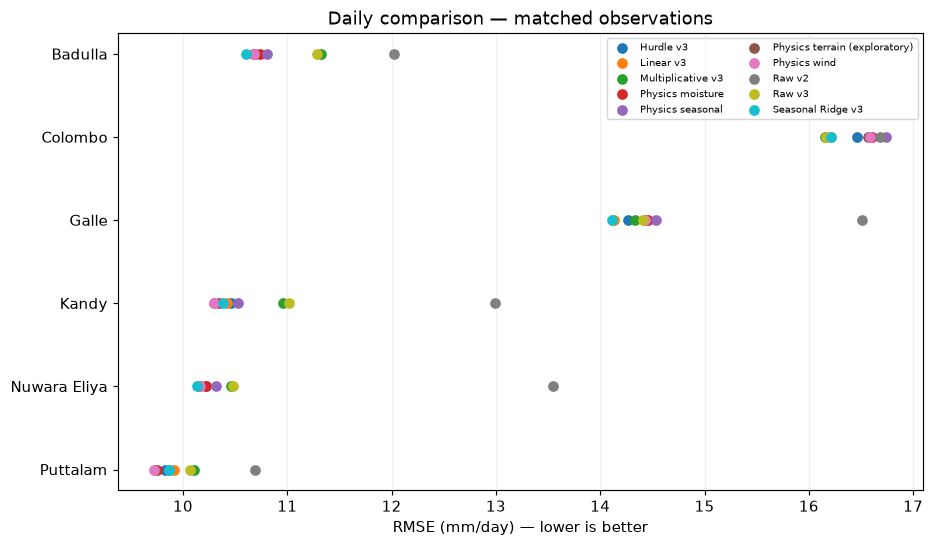

In [9]:
dev_parts=[]
for fold,(ts,te,vs,ve) in enumerate(FOLDS,1):
    for station in STATIONS:
        s=full_valid[full_valid.Station==station]
        tr=s[s.Date.between(ts,te)];va=s[s.Date.between(vs,ve)]
        assert tr.Date.max()<va.Date.min()
        for name in DAILY_MODELS:
            fit=fit_daily(name,tr);pred,prob=predict_daily(fit,va)
            dev_parts.append(pd.DataFrame(dict(Station=station,Date=va.Date.values,Fold=fold,Model=name,
                 Gauge_mm_day=va.Rainfall_mm.values,Prediction_mm_day=pred,
                 Wet_probability=(np.full(len(va),np.nan) if prob is None else prob))))
dev_daily=pd.concat(dev_parts,ignore_index=True)
assert dev_daily.Date.max()<=pd.Timestamp(DEV_END)
assert not dev_daily.duplicated(['Station','Date','Model']).any()
assert dev_daily.groupby(['Station','Model']).size().groupby(level=0).nunique().eq(1).all()
rows=[]
for (station,name),z in dev_daily.groupby(['Station','Model']):
    g=z.Gauge_mm_day.to_numpy(float);pr=z.Prediction_mm_day.to_numpy(float)
    prob=z.Wet_probability.to_numpy(float) if name=='Hurdle v3' else None
    rows.append(dict(Station=station,Model=name,**scores(g,pr),**wet(g,pr,prob=prob),**heavy(g,pr)))
dev_daily_scores=pd.DataFrame(rows);dev_daily_scores['scale']='daily'
daily_selection=select_candidates(dev_daily_scores,['Station'],DAILY_PREFERENCE)
daily_selection['scale']='daily'
print('DEVELOPMENT DAILY SELECTION — NOT HISTORICAL TEST')
display(daily_selection.round(3));daily_selection.to_csv(TABDIR/'02_daily_development_selection.csv',index=False)
dev_daily_scores.to_csv(TABDIR/'03_daily_development_candidates.csv',index=False)
fig,ax=plot_rmse_dot(dev_daily_scores,scale='daily',save_as='01_daily_candidate_rmse_development');plt.show()


## 5 — Complete calendar pentads/months, and Notebook 04 scale-specific models

CHIRPS-aligned pentads use 1–5, 6–10, 11–15, 16–20, 21–25, and **26–month-end**. February's last pentad has 3 days (or 4 in leap years). Monthly intervals contain the correct 28/29/30/31 days. Exclude **incomplete intervals**, including any that cross a split boundary. The model objective is an accumulated total (mm/pentad or mm/month), **not future forecasting**.


In [17]:
paired=p[['Station','Date','Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']].copy().sort_values(['Station','Date'])
assert not paired.duplicated(['Station','Date']).any()
def interval_key(d,scale):
    dt=d.Date
    if scale=='monthly':return dt.dt.to_period('M').dt.to_timestamp()
    start=1+5*((dt.dt.day-1)//5)
    return pd.to_datetime(dict(year=dt.dt.year,month=dt.dt.month,day=start))
def complete_intervals(d,scale):
    x=d.copy();x['interval']=interval_key(x,scale)
    if scale=='monthly':x['expected_days']=x.Date.dt.days_in_month
    else:x['expected_days']=np.where(x.Date.dt.day>=26,x.Date.dt.days_in_month-25,5)
    x=x.dropna(subset=['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm'])
    x=x[(x[['Rainfall_mm','CHIRPS_mm','CHIRPS_V3_mm']]>=0).all(axis=1)]
    a=x.groupby(['Station','interval'],as_index=False).agg(n_days=('Date','nunique'),
        expected_days=('expected_days','first'),Gauge_mm=('Rainfall_mm','sum'),V2_mm=('CHIRPS_mm','sum'),V3_mm=('CHIRPS_V3_mm','sum'))
    a=a[a.n_days.eq(a.expected_days)].copy()
    a['interval_end']=a.interval+pd.to_timedelta(a.expected_days-1,unit='D');a['scale']=scale
    assert not a.duplicated(['Station','interval']).any()
    return a
intervals={scale:complete_intervals(paired,scale) for scale in ['pentad','monthly']}
for scale,d in intervals.items():
    print(scale, 'complete intervals:',len(d));display(d.head(3))
#assert intervals['pentad'].query("Station=='Badulla' and interval=='1992-02-26'").expected_days.iloc[0]==4

# Verify leap-year pentad calculation independently of station completeness
test_dates = pd.DataFrame({
    'Station': ['Test'] * 4,
    'Date': pd.date_range('1992-02-26', '1992-02-29'),
    'Rainfall_mm': [1.0] * 4,
    'CHIRPS_mm': [1.0] * 4,
    'CHIRPS_V3_mm': [1.0] * 4
})

test_pentad = complete_intervals(test_dates, 'pentad')

assert len(test_pentad) == 1
assert test_pentad['expected_days'].iloc[0] == 4
assert test_pentad['n_days'].iloc[0] == 4

print("Leap-year pentad validation passed.")


def scale_seasonal_features(values,dates):
    theta=2*np.pi*pd.to_datetime(dates).dt.dayofyear.to_numpy(float)/365.2425
    return np.column_stack([np.log1p(np.maximum(values,0)),np.sin(theta),np.cos(theta),np.sin(2*theta),np.cos(2*theta)])
def fit_scale(name,tr,train_daily=None):
    x=tr.V3_mm.to_numpy(float);y=tr.Gauge_mm.to_numpy(float)
    if name in ('Raw v2','Raw v3'):return (name,None)
    if name=='Direct multiplicative':return (name,y.sum()/x.sum() if x.sum()>0 else 1.)
    if name=='Direct linear':return (name,LinearRegression().fit(x[:,None],y))
    if name=='Direct seasonal Ridge':
        m=make_pipeline(StandardScaler(),Ridge(alpha=10.))
        m.fit(scale_seasonal_features(x,tr.interval),y);return (name,m)
    if name=='Sum daily linear':
        assert train_daily is not None
        m=LinearRegression().fit(train_daily[['CHIRPS_V3_mm']].to_numpy(),train_daily.Rainfall_mm.to_numpy())
        return (name,m)
    raise ValueError(name)
def predict_scale(fit,va,scale,val_daily=None):
    name,m=fit;x=va.V3_mm.to_numpy(float)
    if name=='Raw v2':return va.V2_mm.to_numpy(float)
    if name=='Raw v3':return x
    if name=='Direct multiplicative':return np.maximum(0,x*m)
    if name=='Direct linear':return np.maximum(0,m.predict(x[:,None]))
    if name=='Direct seasonal Ridge':return np.maximum(0,m.predict(scale_seasonal_features(x,va.interval)))
    if name=='Sum daily linear':
        assert val_daily is not None
        z=val_daily.copy();z['interval']=interval_key(z,scale)
        z['corrected']=np.maximum(0,m.predict(z[['CHIRPS_V3_mm']].to_numpy()))
        agg=z.groupby(['Station','interval']).agg(sum_pred=('corrected','sum'),n=('Date','nunique'))
        matched=va[['Station','interval','expected_days']].merge(agg,left_on=['Station','interval'],right_index=True,how='left',validate='one_to_one')
        assert matched.n.eq(matched.expected_days).all()
        return matched.sum_pred.to_numpy(float)
    raise ValueError(name)


pentad complete intervals: 7746


,Station,interval,n_days,expected_days,Gauge_mm,V2_mm,V3_mm,interval_end,scale
0,Badulla,1981-01-01,5,5,72.4,91.552375,40.335463,1981-01-05,pentad
1,Badulla,1981-01-06,5,5,0.0,0.000000,0.808782,1981-01-10,pentad
2,Badulla,1981-01-11,5,5,0.0,0.000000,1.350208,1981-01-15,pentad


monthly complete intervals: 1386


,Station,interval,n_days,expected_days,Gauge_mm,V2_mm,V3_mm,interval_end,scale
0,Badulla,1981-01-01,31,31,74.8,91.552375,65.549662,1981-01-31,monthly
1,Badulla,1981-02-01,28,28,110.0,60.784108,79.354974,1981-02-28,monthly
2,Badulla,1981-03-01,31,31,70.2,67.372613,75.453749,1981-03-31,monthly


Leap-year pentad validation passed.


## 6 — Scale-specific rolling validation and model selection

For each station and interval, evaluate raw v2, raw v3, directly fitted linear/multiplicative/seasonal Ridge, and the sum of a **train-only** fitted daily linear correction. The 1% near-tie rule prefers simpler candidates. Because all models use the same complete interval keys, scores are matched and comparable **within a scale**.


DEVELOPMENT SCALE SELECTION — TEST YEARS STILL EXCLUDED


,scale,Station,Selected_model,Validation_RMSE,Raw_v3_validation_RMSE,Validation_improvement_percent,n_validation
0,monthly,Badulla,Raw v3,55.953,55.953,0.000,94
1,monthly,Colombo,Raw v3,69.333,69.333,0.000,90
2,monthly,Galle,Direct multiplicative,65.282,65.945,1.004,94
3,monthly,Kandy,Raw v3,40.818,40.818,0.000,95
4,monthly,Nuwaraeliya,Raw v3,44.973,44.973,0.000,89
5,monthly,Puttalam,Raw v3,41.688,41.688,0.000,92
6,pentad,Badulla,Direct linear,26.225,27.163,3.451,520
7,pentad,Colombo,Raw v3,37.315,37.315,0.000,511
8,pentad,Galle,Direct linear,33.058,35.322,6.408,519
9,pentad,Kandy,Direct linear,26.472,28.414,6.834,519


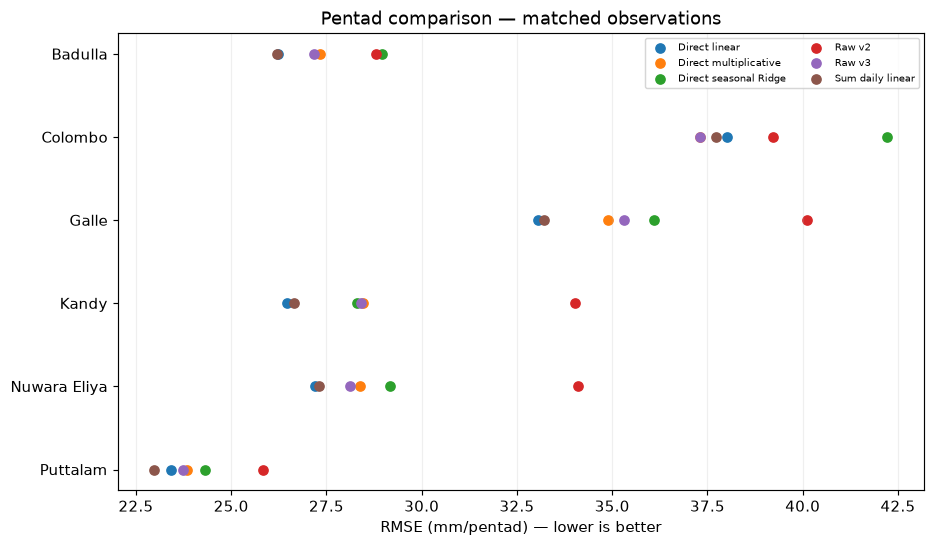

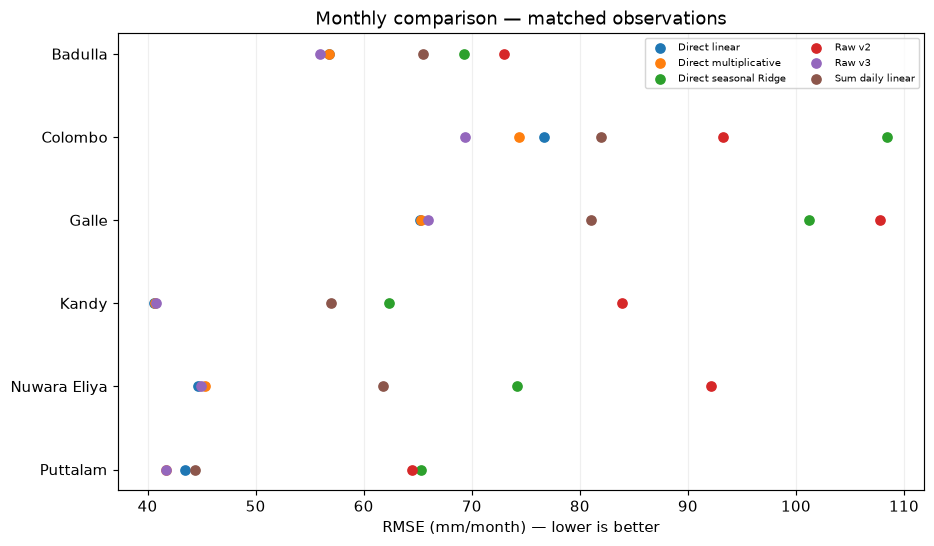

In [19]:
scale_dev_parts=[]
for fold,(ts,te,vs,ve) in enumerate(FOLDS,1):
    tr_daily=paired[paired.Date.between(ts,te)]
    va_daily=paired[paired.Date.between(vs,ve)]
    for scale,all_intervals in intervals.items():
        for station in STATIONS:
            tr=all_intervals[(all_intervals.Station==station)&(all_intervals.interval>=pd.Timestamp(ts))&(all_intervals.interval_end<=pd.Timestamp(te))]
            va=all_intervals[(all_intervals.Station==station)&(all_intervals.interval>=pd.Timestamp(vs))&(all_intervals.interval_end<=pd.Timestamp(ve))]
            train_days=tr_daily[tr_daily.Station==station];val_days=va_daily[va_daily.Station==station]
            for name in SCALE_MODELS:
                fit=fit_scale(name,tr,train_days)
                pr=predict_scale(fit,va,scale,val_days)
                scale_dev_parts.append(pd.DataFrame(dict(scale=scale,Station=station,fold=fold,interval=va.interval.values,
                  Gauge_mm=va.Gauge_mm.values,Model=name,Prediction_mm=pr)))
scale_dev=pd.concat(scale_dev_parts,ignore_index=True)
assert not scale_dev.duplicated(['scale','Station','interval','Model']).any()
rows=[]
for (scale,station,model),d in scale_dev.groupby(['scale','Station','Model']):
    rows.append(dict(scale=scale,Station=station,Model=model,**scores(d.Gauge_mm,d.Prediction_mm)))
scale_scores=pd.DataFrame(rows)
scale_selection=select_candidates(scale_scores,['scale','Station'],SCALE_PREFERENCE)
print('DEVELOPMENT SCALE SELECTION — TEST YEARS STILL EXCLUDED');display(scale_selection.round(3))
scale_scores.to_csv(TABDIR/'04_scale_development_candidates.csv',index=False)
scale_selection.to_csv(TABDIR/'05_scale_development_selection.csv',index=False)
for scale in ['pentad','monthly']:
    fig,ax=plot_rmse_dot(scale_scores,scale=scale,save_as=f'02_{scale}_development_rmse');plt.show()


## 7 — Freeze choices and evaluate 1995–2000 once

Here the **same named model formulations** are refitted on 1981–1994 before predicting 1995–2000. This follows the selected procedure rather than reusing a particular fitted fold. Raw v2 and raw v3 are always evaluated as baselines on the same dates. **Do not edit model choices after viewing test results.** If you investigate alternatives afterwards, report that work as exploratory.


In [21]:
selected_daily=dict(zip(daily_selection.Station,daily_selection.Selected_model))
selected_scale={(r.scale,r.Station):r.Selected_model for r in scale_selection.itertuples(index=False)}
assert len(selected_daily)==6 and len(selected_scale)==12
print('FROZEN DAILY:',selected_daily)
print('FROZEN PENTAD/MONTHLY:',selected_scale)

test_daily_parts=[]
for station in STATIONS:
    s=full_valid[full_valid.Station==station]
    tr=s[s.Date.le(DEV_END)];va=s[s.Date.between(TEST_START,TEST_END)]
    for name in dict.fromkeys(['Raw v2','Raw v3',selected_daily[station]]):
        fit=fit_daily(name,tr);pr,prob=predict_daily(fit,va)
        test_daily_parts.append(pd.DataFrame(dict(Station=station,Date=va.Date.values,Model=name,
             Gauge_mm_day=va.Rainfall_mm.values,Prediction_mm_day=pr,
             Wet_probability=prob if prob is not None else np.full(len(va),np.nan))))
test_daily=pd.concat(test_daily_parts,ignore_index=True)
assert test_daily.Date.min()>=pd.Timestamp(TEST_START) and test_daily.Date.max()<=pd.Timestamp(TEST_END)
assert not test_daily.duplicated(['Station','Date','Model']).any()

scale_test_parts=[]
for scale,a in intervals.items():
    for station in STATIONS:
        tr=a[(a.Station==station)&(a.interval_end<=pd.Timestamp(DEV_END))]
        va=a[(a.Station==station)&(a.interval>=pd.Timestamp(TEST_START))&(a.interval_end<=pd.Timestamp(TEST_END))]
        tr_days=paired[(paired.Station==station)&(paired.Date.le(DEV_END))]
        va_days=paired[(paired.Station==station)&(paired.Date.between(TEST_START,TEST_END))]
        for name in dict.fromkeys(['Raw v2','Raw v3',selected_scale[(scale,station)]]):
            fit=fit_scale(name,tr,tr_days);pr=predict_scale(fit,va,scale,va_days)
            scale_test_parts.append(pd.DataFrame(dict(scale=scale,Station=station,interval=va.interval.values,
                 Model=name,Gauge_mm=va.Gauge_mm.values,Prediction_mm=pr)))
test_scale=pd.concat(scale_test_parts,ignore_index=True)
assert not test_scale.duplicated(['scale','Station','interval','Model']).any()
print('Historical test daily rows:',len(test_daily),'scale rows:',len(test_scale))
test_daily.to_csv(TABDIR/'06_historical_daily_predictions.csv',index=False)
test_scale.to_csv(TABDIR/'07_historical_scale_predictions.csv',index=False)


FROZEN DAILY: {'Badulla': 'Linear v3', 'Colombo': 'Raw v3', 'Galle': 'Linear v3', 'Kandy': 'Seasonal Ridge v3', 'Nuwaraeliya': 'Linear v3', 'Puttalam': 'Physics moisture'}
FROZEN PENTAD/MONTHLY: {('monthly', 'Badulla'): 'Raw v3', ('monthly', 'Colombo'): 'Raw v3', ('monthly', 'Galle'): 'Direct multiplicative', ('monthly', 'Kandy'): 'Raw v3', ('monthly', 'Nuwaraeliya'): 'Raw v3', ('monthly', 'Puttalam'): 'Raw v3', ('pentad', 'Badulla'): 'Direct linear', ('pentad', 'Colombo'): 'Raw v3', ('pentad', 'Galle'): 'Direct linear', ('pentad', 'Kandy'): 'Direct linear', ('pentad', 'Nuwaraeliya'): 'Direct linear', ('pentad', 'Puttalam'): 'Sum daily linear'}
Historical test daily rows: 37211 scale rows: 7477


## 8 — Test scores, trade-offs and model recommendations

Every row states the sample count, period, unit and raw-v3 reference. Daily occurrence uses **≥1 mm/day** for raw products and amount-based models; for the hurdle candidate, the probability-rule classification is reported clearly. Gauge-heavy-days ≥25 mm/day are used **only for evaluating**, never as model inputs.


In [23]:
test_rows=[]
for (station,name),d in test_daily.groupby(['Station','Model']):
    g=d.Gauge_mm_day.to_numpy(float);pr=d.Prediction_mm_day.to_numpy(float)
    probability=d.Wet_probability.to_numpy(float) if name=='Hurdle v3' else None
    test_rows.append(dict(scale='daily',Station=station,Model=name,**scores(g,pr),
                          **wet(g,pr,prob=probability),**heavy(g,pr)))
for (scale,station,name),d in test_scale.groupby(['scale','Station','Model']):
    test_rows.append(dict(scale=scale,Station=station,Model=name,**scores(d.Gauge_mm,d.Prediction_mm)))
test_scores=pd.DataFrame(test_rows)
summary=[]
all_selection=pd.concat([daily_selection[['Station','scale','Selected_model','Validation_RMSE','Validation_improvement_percent','n_validation']],
                         scale_selection[['Station','scale','Selected_model','Validation_RMSE','Validation_improvement_percent','n_validation']]],ignore_index=True)
for r in all_selection.itertuples(index=False):
    data=test_scores[(test_scores.Station==r.Station)&(test_scores.scale==r.scale)]
    raw_score=data.loc[data.Model.eq('Raw v3')].iloc[0]
    selected_score=data.loc[data.Model.eq(r.Selected_model)].iloc[0]
    row=dict(Station=r.Station,scale=r.scale,Selected_model=r.Selected_model,
             validation_n=r.n_validation,validation_RMSE=r.Validation_RMSE,
             validation_improvement_percent=r.Validation_improvement_percent,
             test_n=int(selected_score.n),Raw_v3_test_RMSE=raw_score.RMSE,
             Selected_test_RMSE=selected_score.RMSE,Test_MAE=selected_score.MAE,
             Test_Bias=selected_score.Bias,Test_Pearson_r=selected_score.Pearson_r,
             Test_RMSE_improvement_percent=100*(raw_score.RMSE-selected_score.RMSE)/raw_score.RMSE)
    if r.scale=='daily':
        row.update(Raw_CSI=raw_score.CSI,Selected_CSI=selected_score.CSI,
                   Raw_heavy_RMSE=raw_score.Heavy_RMSE,Selected_heavy_RMSE=selected_score.Heavy_RMSE,
                   Heavy_n=int(selected_score.Heavy_n))
    summary.append(row)
recommendations=pd.DataFrame(summary)
assert len(recommendations)==18
print('SELECTED BY DEVELOPMENT, EVALUATED ON HISTORICAL TEST (1995–2000)')
for scale in ['daily','pentad','monthly']:
    units={'daily':'mm/day','pentad':'mm/pentad','monthly':'mm/month'}
    print(f'\n{scale.upper()}: RMSE in {units[scale]}')
    display(recommendations[recommendations.scale.eq(scale)].round(3))
recommendations.to_csv(TABDIR/'08_final_station_scale_recommendations.csv',index=False)
test_scores.to_csv(TABDIR/'09_historical_test_metrics.csv',index=False)


SELECTED BY DEVELOPMENT, EVALUATED ON HISTORICAL TEST (1995–2000)

DAILY: RMSE in mm/day


,Station,scale,Selected_model,validation_n,validation_RMSE,validation_improvement_percent,test_n,Raw_v3_test_RMSE,Selected_test_RMSE,Test_MAE,Test_Bias,Test_Pearson_r,Test_RMSE_improvement_percent,Raw_CSI,Selected_CSI,Raw_heavy_RMSE,Selected_heavy_RMSE,Heavy_n
0,Badulla,daily,Linear v3,2918,10.672,5.396,2191,10.189,9.412,5.202,0.387,0.456,7.629,0.477,0.335,30.457,32.778,121.0
1,Colombo,daily,Raw v3,2897,16.162,0.000,2191,14.543,14.543,7.203,0.483,0.503,0.000,0.507,0.507,42.248,42.248,169.0
2,Galle,daily,Linear v3,2913,14.134,1.948,2192,13.747,13.374,6.894,-0.351,0.482,2.713,0.529,0.437,40.194,43.486,161.0
3,Kandy,daily,Seasonal Ridge v3,2921,10.380,5.756,2190,10.829,10.299,5.564,0.087,0.436,4.888,0.496,0.394,35.603,38.347,115.0
4,Nuwaraeliya,daily,Linear v3,2915,10.175,2.888,2180,10.261,9.811,5.668,-0.095,0.426,4.384,0.562,0.456,30.681,32.294,135.0
5,Puttalam,daily,Physics moisture,2912,9.752,3.132,2190,10.043,10.620,3.967,0.512,0.443,-5.746,0.372,0.343,45.481,52.887,72.0



PENTAD: RMSE in mm/pentad


,Station,scale,Selected_model,validation_n,validation_RMSE,validation_improvement_percent,test_n,Raw_v3_test_RMSE,Selected_test_RMSE,Test_MAE,Test_Bias,Test_Pearson_r,Test_RMSE_improvement_percent,Raw_CSI,Selected_CSI,Raw_heavy_RMSE,Selected_heavy_RMSE,Heavy_n
12,Badulla,pentad,Direct linear,520,26.225,3.451,389,27.707,25.530,17.027,2.039,0.645,7.855,NaN,NaN,NaN,NaN,NaN
13,Colombo,pentad,Raw v3,511,37.315,0.000,389,36.353,36.353,24.140,2.768,0.687,0.000,NaN,NaN,NaN,NaN,NaN
14,Galle,pentad,Direct linear,519,33.058,6.408,390,36.176,33.686,21.675,-1.990,0.684,6.883,NaN,NaN,NaN,NaN,NaN
15,Kandy,pentad,Direct linear,519,26.472,6.834,388,29.082,27.090,18.093,0.411,0.589,6.851,NaN,NaN,NaN,NaN,NaN
16,Nuwaraeliya,pentad,Direct linear,513,27.191,3.315,378,28.794,26.643,19.198,0.275,0.590,7.471,NaN,NaN,NaN,NaN,NaN
17,Puttalam,pentad,Sum daily linear,518,22.984,3.126,388,26.198,26.049,13.645,1.127,0.673,0.571,NaN,NaN,NaN,NaN,NaN



MONTHLY: RMSE in mm/month


,Station,scale,Selected_model,validation_n,validation_RMSE,validation_improvement_percent,test_n,Raw_v3_test_RMSE,Selected_test_RMSE,Test_MAE,Test_Bias,Test_Pearson_r,Test_RMSE_improvement_percent,Raw_CSI,Selected_CSI,Raw_heavy_RMSE,Selected_heavy_RMSE,Heavy_n
6,Badulla,monthly,Raw v3,94,55.953,0.000,71,47.544,47.544,38.472,14.301,0.888,0.000,NaN,NaN,NaN,NaN,NaN
7,Colombo,monthly,Raw v3,90,69.333,0.000,71,60.034,60.034,43.655,14.166,0.917,0.000,NaN,NaN,NaN,NaN,NaN
8,Galle,monthly,Direct multiplicative,94,65.282,1.004,72,54.809,55.817,43.133,-9.098,0.928,-1.838,NaN,NaN,NaN,NaN,NaN
9,Kandy,monthly,Raw v3,95,40.818,0.000,70,48.332,48.332,35.474,6.330,0.872,0.000,NaN,NaN,NaN,NaN,NaN
10,Nuwaraeliya,monthly,Raw v3,89,44.973,0.000,60,49.778,49.778,37.317,-7.409,0.865,0.000,NaN,NaN,NaN,NaN,NaN
11,Puttalam,monthly,Raw v3,92,41.688,0.000,70,35.744,35.744,25.813,7.883,0.937,0.000,NaN,NaN,NaN,NaN,NaN


## 9 — Reusable scientific visualizations and exploratory uncertainty

Plots:
1. **RMSE improvement dot plot** (test; changes can be negative).
2. **Gauge versus raw/selected time series** for a chosen station.
3. **Daily wet-day / heavy-rainfall trade-off**.
4. **Year-block bootstrap 95% intervals** for selected-vs-raw test RMSE differences, conditional on the already-fixed model selection. With only six annual blocks and earlier test-period inspection, intervals are exploratory, **not confirmatory hypothesis tests**.

Unlike raw-versus-selected validation rankings, these graphics are descriptions of a historical evaluation and must not drive further tuning.


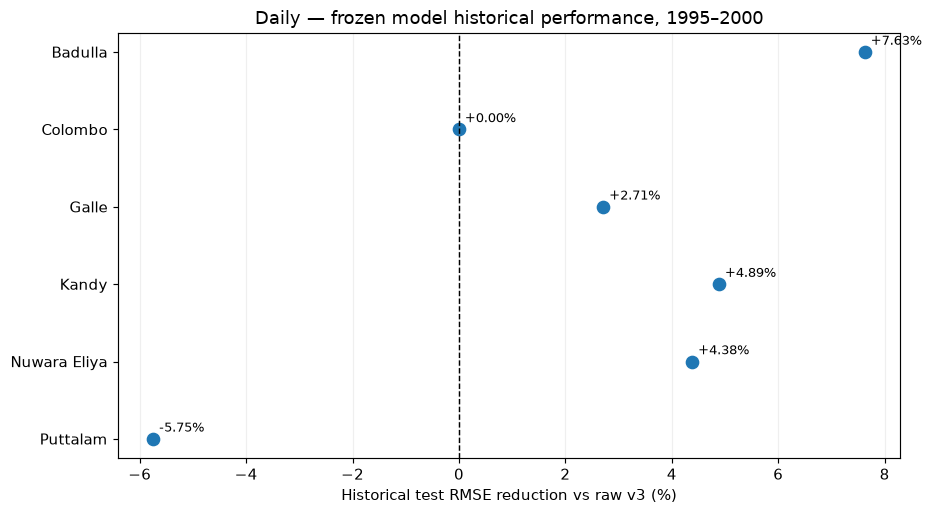

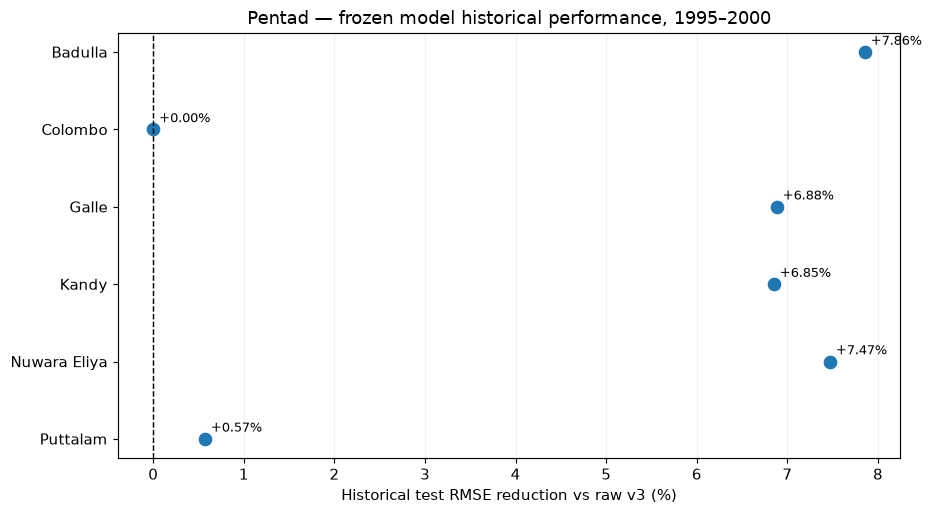

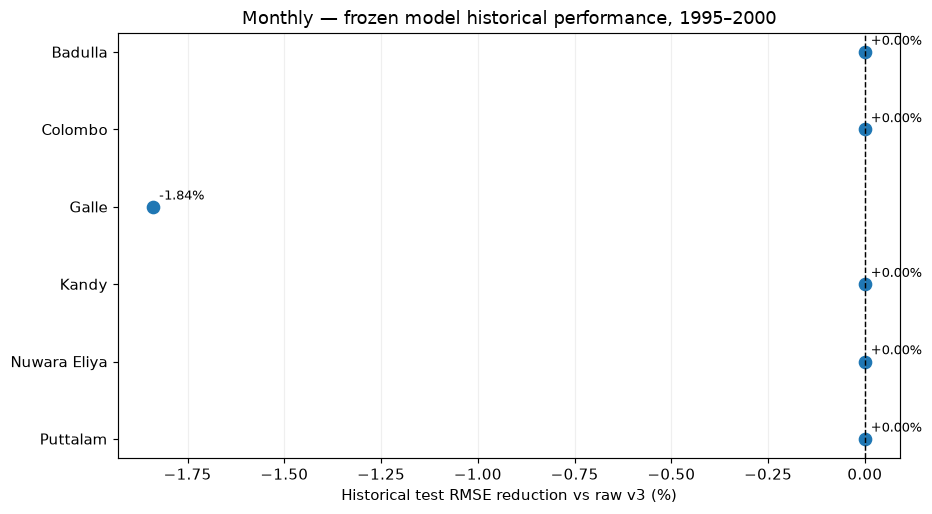

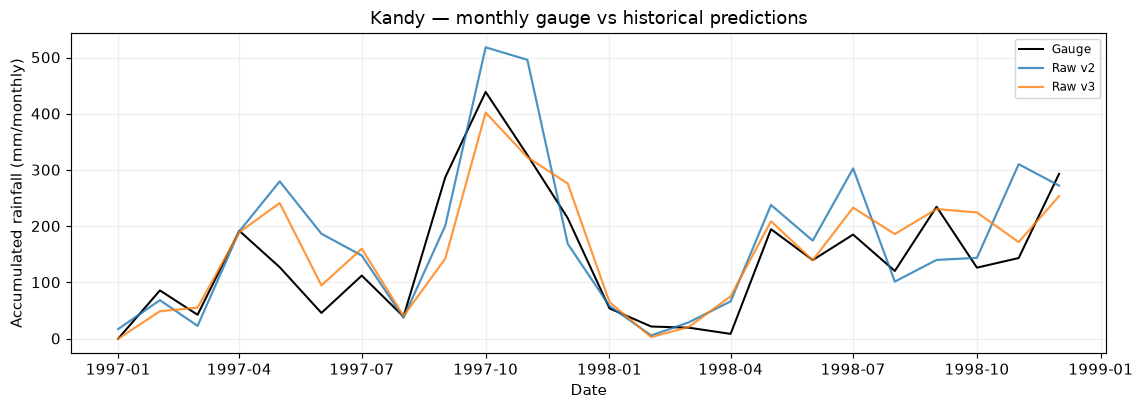

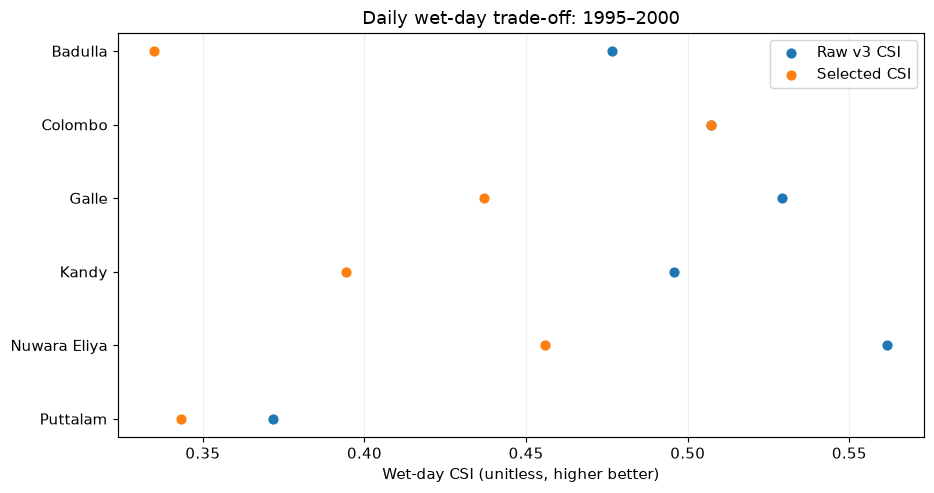

In [25]:
def plot_recommendation_improvement(summary,scale='daily',save_as=None):
    d=summary[summary.scale.eq(scale)].set_index('Station').reindex(STATIONS)
    fig,ax=plt.subplots(figsize=(9,5))
    y=np.arange(6);vals=d.Test_RMSE_improvement_percent.values
    ax.scatter(vals,y,s=70);ax.axvline(0,ls='--',color='black',lw=1)
    for i,v in enumerate(vals):ax.annotate(f'{v:+.2f}%',(v,i),xytext=(4,5),textcoords='offset points',fontsize=9)
    ax.set_yticks(y,[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set_xlabel('Historical test RMSE reduction vs raw v3 (%)');ax.set_title(scale.capitalize()+' — frozen model historical performance, 1995–2000')
    ax.grid(axis='x',alpha=.2);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

def plot_historical_timeseries(test_data,station='Kandy',scale='monthly',start='1997-01-01',end='1998-12-31',save_as=None):
    timecol='Date' if scale=='daily' else 'interval'
    observed='Gauge_mm_day' if scale=='daily' else 'Gauge_mm'
    predicted='Prediction_mm_day' if scale=='daily' else 'Prediction_mm'
    x=test_data[(test_data.Station==station)&test_data[timecol].between(start,end)].copy()
    fig,ax=plt.subplots(figsize=(11,4))
    g=x.groupby(timecol)[observed].first().sort_index()
    ax.plot(g.index,g.values,label='Gauge',color='black',lw=1.4)
    for model,z in x.groupby('Model'):
        q=z.sort_values(timecol);ax.plot(q[timecol],q[predicted],label=model,alpha=.8)
    ax.set(xlabel='Date',ylabel=('Rainfall (mm/day)' if scale=='daily' else 'Accumulated rainfall (mm/'+scale+')'),
           title=f'{station} — {scale} gauge vs historical predictions');ax.legend(fontsize=8);ax.grid(alpha=.2);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax

for scale in ['daily','pentad','monthly']:
    fig,ax=plot_recommendation_improvement(recommendations,scale,save_as=f'03_{scale}_test_percent_change');plt.show()
fig,ax=plot_historical_timeseries(test_scale[test_scale.scale.eq('monthly')],station='Kandy',scale='monthly',save_as='04_Kandy_monthly_historical');plt.show()

trade=recommendations[recommendations.scale.eq('daily')].set_index('Station').reindex(STATIONS)
fig,ax=plt.subplots(figsize=(9,4.8));ys=np.arange(6)
ax.scatter(trade.Raw_CSI,ys,label='Raw v3 CSI');ax.scatter(trade.Selected_CSI,ys,label='Selected CSI')
ax.set_yticks(ys,[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
ax.set_xlabel('Wet-day CSI (unitless, higher better)');ax.set_title('Daily wet-day trade-off: 1995–2000');ax.legend();ax.grid(axis='x',alpha=.2);fig.tight_layout();save_fig(fig,'05_daily_wetday_CSI');plt.show()


EXPLORATORY conditional-on-selection intervals. Do not claim independent significance.


,Station,scale,Model,n,n_years,Delta_RMSE,CI_low,CI_high
0,Badulla,daily,Linear v3,2191,6,0.777,0.457,1.085
1,Colombo,daily,Raw v3,2191,6,0.000,0.000,0.000
2,Galle,daily,Linear v3,2192,6,0.373,-0.178,0.796
3,Kandy,daily,Seasonal Ridge v3,2190,6,0.529,0.146,0.783
4,Nuwaraeliya,daily,Linear v3,2180,6,0.450,0.099,0.728
5,Puttalam,daily,Physics moisture,2190,6,-0.577,-1.789,0.509
6,Badulla,monthly,Raw v3,71,6,0.000,0.000,0.000
7,Colombo,monthly,Raw v3,71,6,0.000,0.000,0.000
8,Galle,monthly,Direct multiplicative,72,6,-1.008,-2.528,0.235
9,Kandy,monthly,Raw v3,70,6,0.000,0.000,0.000


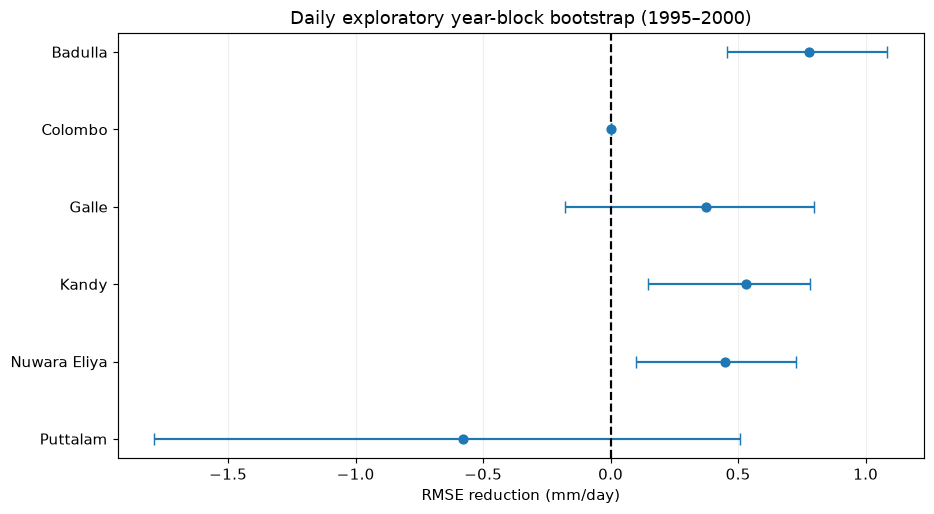

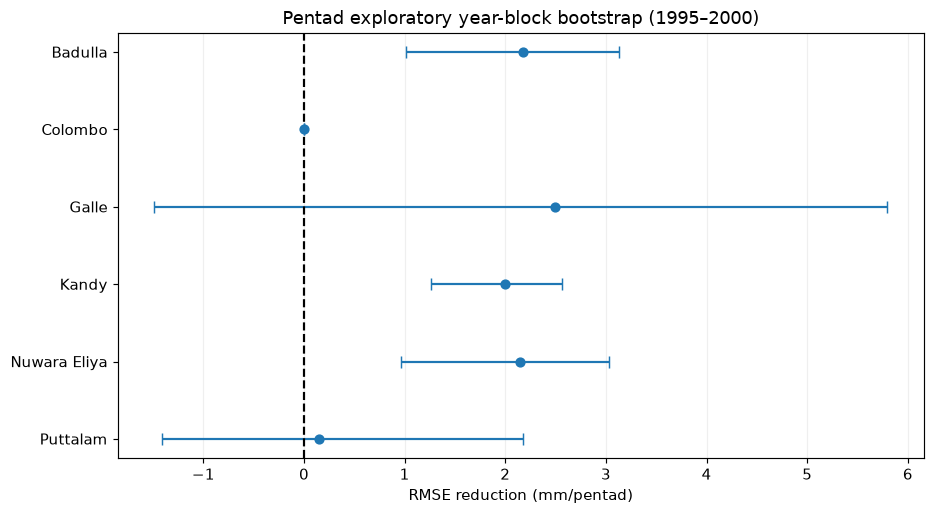

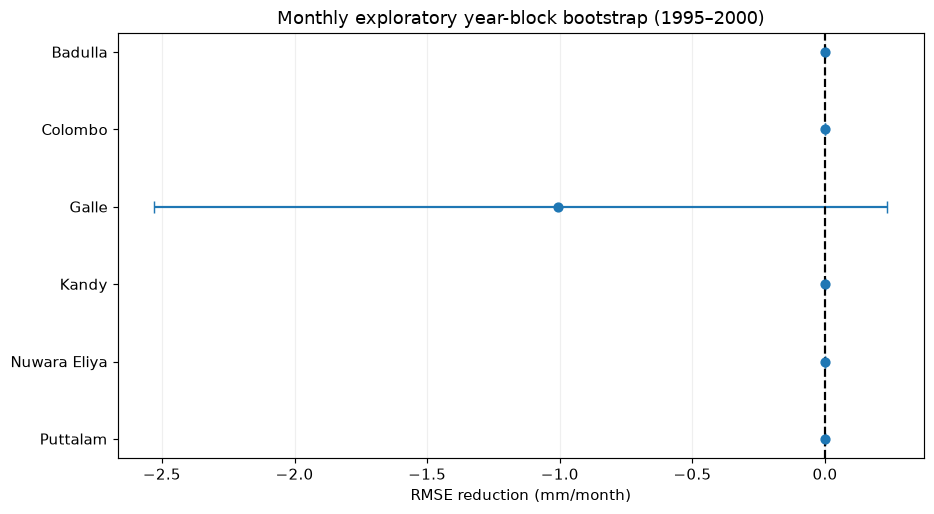

In [27]:
def historical_block_bootstrap(daily_test,scale_test,recs,n_boot=2000,seed=42):
    rng=np.random.default_rng(seed);out=[]
    for r in recs.itertuples(index=False):
        x=(daily_test if r.scale=='daily' else scale_test[scale_test.scale.eq(r.scale)])
        key='Date' if r.scale=='daily' else 'interval'
        truth='Gauge_mm_day' if r.scale=='daily' else 'Gauge_mm'
        estimate='Prediction_mm_day' if r.scale=='daily' else 'Prediction_mm'
        subset=x[x.Station==r.Station]
        a=subset[subset.Model=='Raw v3'][[key,truth,estimate]].rename(columns={estimate:'raw'})
        b=subset[subset.Model==r.Selected_model][[key,truth,estimate]].rename(columns={truth:'g2',estimate:'selected'})
        z=a.merge(b,on=key,validate='one_to_one');assert np.allclose(z[truth],z.g2)
        z['Year']=z[key].dt.year
        blocks=[grp for _,grp in z.groupby('Year')]
        def delta(v):
            return scores(v[truth],v.raw)['RMSE']-scores(v[truth],v.selected)['RMSE']
        obs=delta(z);boot=np.empty(n_boot)
        for i in range(n_boot):
            draw=rng.integers(0,len(blocks),len(blocks))
            sample=pd.concat([blocks[j] for j in draw],ignore_index=True)
            boot[i]=delta(sample)
        lo,hi=np.quantile(boot,[.025,.975])
        out.append(dict(Station=r.Station,scale=r.scale,Model=r.Selected_model,n=len(z),
                        n_years=len(blocks),Delta_RMSE=obs,CI_low=lo,CI_high=hi))
    return pd.DataFrame(out)
boot=historical_block_bootstrap(test_daily,test_scale,recommendations,n_boot=2000)
boot.to_csv(TABDIR/'10_exploratory_historical_year_bootstrap.csv',index=False)
print('EXPLORATORY conditional-on-selection intervals. Do not claim independent significance.')
display(boot.round(3))

def plot_bootstrap(boot,scale='daily',save_as=None):
    d=boot[boot.scale.eq(scale)].set_index('Station').reindex(STATIONS)
    y=np.arange(6);v=d.Delta_RMSE.to_numpy(float);lo=d.CI_low.to_numpy(float);hi=d.CI_high.to_numpy(float)
    fig,ax=plt.subplots(figsize=(9,5));ax.errorbar(v,y,xerr=np.vstack([np.maximum(0,v-lo),np.maximum(0,hi-v)]),fmt='o',capsize=4)
    ax.axvline(0,color='black',ls='--');ax.set_yticks(y,[s.replace('Nuwaraeliya','Nuwara Eliya') for s in STATIONS]);ax.invert_yaxis()
    ax.set_xlabel('RMSE reduction ('+{'daily':'mm/day','pentad':'mm/pentad','monthly':'mm/month'}[scale]+')')
    ax.set_title(scale.capitalize()+' exploratory year-block bootstrap (1995–2000)');ax.grid(axis='x',alpha=.2);fig.tight_layout()
    if save_as:save_fig(fig,save_as)
    return fig,ax
for scale in ['daily','pentad','monthly']:
    fig,ax=plot_bootstrap(boot,scale,save_as=f'06_{scale}_historical_bootstrap');plt.show()


## 10 — Final scientific decision matrix, interpretation checklist and evidence trail

The final table `08_final_station_scale_recommendations.csv` is the source of truth for the 18 station × scale recommendations. **A recommendation specifies the selected procedure, not universal predictive superiority.** Check for negative test improvements and wet-day/extreme-rainfall trade-offs.

Interpretation checklist:

1. For each station, which version/model had the best **development-period** RMSE? Was raw CHIRPS v3 retained under the predeclared 1% near-tie rule?
2. On 1995–2000, did that frozen model actually improve daily/pentad/monthly RMSE? Quote sample counts and **correct units**.
3. Which daily calibration models reduced RMSE but harmed CSI, heavy-rainfall RMSE or MAE? Do **not** describe them as unqualified improvements.
4. At pentad/monthly scales, does **direct correction** improve over summing corrected daily rainfall? Was raw v3 already adequate?
5. Did the exploratory year-block intervals cross zero? Six test-year blocks and prior historical test inspection limit inference.
6. Spatial buffering and LOSO generalization are **different questions**. Notebook 02's spatial support results and Notebook 05's held-out stations must not be silently substituted for station-specific calibration results.
7. Final model conclusions refer to **retrospective rainfall postprocessing**. A same-day CHIRPS or ERA5 model is not automatically a future rainfall forecast.

### Source code and literature
- Notebook 01: mandatory gauge/CHIRPS QC and simple independent validation.
- Notebook 02: matched product comparison, CHIRPS calendar pentads, buffering.
- Notebook 03: daily Ridge, linear, multiplicative and logistic–Gamma models.
- Notebook 04: direct accumulated rainfall and daily-sum corrections; ADF/KPSS/SARIMA/ETS are **separate forecasting diagnostics**.
- Notebook 05: ERA5 predictors, Copernicus terrain and LOSO.
- Funk et al. (2015), CHIRPS v2, *Scientific Data*. https://doi.org/10.1038/sdata.2015.66
- Funk et al. (2026), CHIRPS v3, *Scientific Data*. https://doi.org/10.1038/s41597-026-07096-4
- Hersbach et al. (2020), ERA5, *Quarterly Journal of the Royal Meteorological Society*. https://doi.org/10.1002/qj.3803
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, 3rd ed. https://otexts.com/fpp3/
- Google Earth Engine: [CHIRPS v2](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY), [CHIRPS v3 RNL](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL), [Copernicus DEM GLO-30](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_DEM_GLO30).

**Research integrity note:** Existing studies may have contributed gauges to CHIRPS assimilation, terrain proxies are approximate, observational day alignment may differ, and 1995–2000 was already inspected. Present results as a historical, exploratory evaluation—not a new independent external validation.


### Draft your final written conclusion **after** inspecting the output table

> Using four development-period rolling-origin folds, we selected one daily, one pentad and one monthly rainfall procedure for each of six stations. We then refitted the chosen procedures on 1981–1994 and evaluated them on paired 1995–2000 observations. [Insert the actual station-specific winners, RMSE improvements and uncertainty qualifications from the output tables.] The selected daily models [insert whether wet-day CSI and heavy-rainfall RMSE improved or worsened]. The findings indicate [state whether scale-specific modelling helped]. The evaluation is exploratory because the historical test period was inspected previously; station–grid mismatch, potential gauge assimilation and the small number of independent years limit generalization.

Do **not** populate this paragraph using the test set to revise model choices. Keep unsuccessful models and contradictory metrics visible.


In [29]:
STATION_TO_PLOT = 'Badulla'
SCALE_TO_PLOT = 'pentad'
START_TO_PLOT = '1997-01-01'
END_TO_PLOT = '1998-12-31'